In [3]:
import pandas as pd
import numpy as np
import joblib
import os

# Load preprocessed datasets

X_train = pd.read_csv("../datasets/processed_data/X_train.csv")
X_test = pd.read_csv("../datasets/processed_data/X_test.csv")
y_train = pd.read_csv("../datasets/processed_data/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../datasets/processed_data/y_test.csv").squeeze("columns")

# Display dataset information
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nDataset Loaded Successfully!")

Training Data Shape: (8000, 11)
Testing Data Shape: (2000, 11)

Training Target Shape: (8000,)
Testing Target Shape: (2000,)

Dataset Loaded Successfully!


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             classification_report,
                             confusion_matrix)

# Initialize the Logistic Regression
log_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)

# Train the model
log_model.fit(X_train, y_train)

#Make predictions
y_pred = log_model.predict(X_test)
y_prob_log = log_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("LOGISTIC REGRESSION RESULTS")
print("----------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("AUC-ROC:", roc_auc_score(y_test, y_prob_log))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

LOGISTIC REGRESSION RESULTS
----------------------------
Accuracy: 0.7135
Precision: 0.38722826086956524
Recall: 0.7002457002457002
F1-Score: 0.49868766404199477
AUC-ROC: 0.7771191838988449

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000


Confusion Matrix:
[[1142  451]
 [ 122  285]]


In [5]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree 
dt_model = DecisionTreeClassifier(max_depth=6, min_samples_split=20, min_samples_leaf=10, class_weight="balanced", random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("DECISION TREE RESULTS")
print("----------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1-Score:", f1_score(y_test, y_pred_dt))
print("AUC-ROC:", roc_auc_score(y_test, y_prob_dt))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

DECISION TREE RESULTS
----------------------------
Accuracy: 0.7615
Precision: 0.44971264367816094
Recall: 0.769041769041769
F1-Score: 0.5675430643699003
AUC-ROC: 0.8397920262327041

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.76      0.84      1593
           1       0.45      0.77      0.57       407

    accuracy                           0.76      2000
   macro avg       0.69      0.76      0.70      2000
weighted avg       0.83      0.76      0.78      2000


Confusion Matrix:
[[1210  383]
 [  94  313]]


In [6]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=20, min_samples_leaf=10, class_weight="balanced", random_state=42, n_jobs=-1)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("RANDOM FOREST RESULTS")
print("----------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("AUC:", roc_auc_score(y_test, y_prob_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST RESULTS
----------------------------
Accuracy: 0.809
AUC: 0.8629399815840495
Precision: 0.5216637781629117
Recall: 0.7395577395577395
F1-Score: 0.6117886178861789

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.87      1593
           1       0.52      0.74      0.61       407

    accuracy                           0.81      2000
   macro avg       0.72      0.78      0.74      2000
weighted avg       0.84      0.81      0.82      2000


Confusion Matrix:
[[1317  276]
 [ 106  301]]


In [7]:
import pandas as pd

# Compare all trained models
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_rf)],
    'AUC': [roc_auc_score(y_test, y_prob_log), roc_auc_score(y_test, y_prob_dt), roc_auc_score(y_test, y_prob_rf)],
    'Precision': [precision_score(y_test, y_pred), precision_score(y_test, y_pred_dt), precision_score(y_test, y_pred_rf)],
    'Recall': [recall_score(y_test, y_pred), recall_score(y_test, y_pred_dt), recall_score(y_test, y_pred_rf)],
    'F1-Score': [f1_score(y_test, y_pred), f1_score(y_test, y_pred_dt), f1_score(y_test, y_pred_rf)]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1-Score
0,Logistic Regression,0.7135,0.7771,0.3872,0.7002,0.4987
1,Decision Tree,0.7615,0.8398,0.4497,0.7690,0.5675
2,Random Forest,0.8090,0.8629,0.5217,0.7396,0.6118


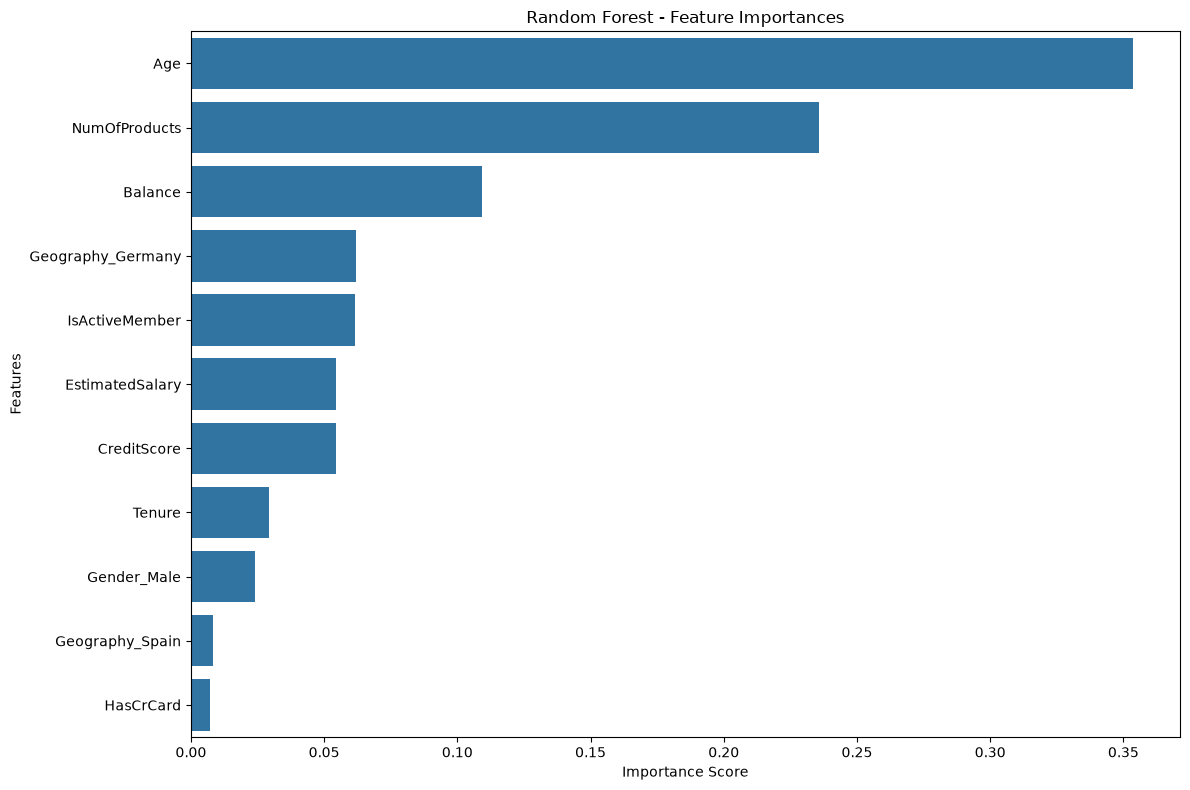

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importances 
feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)

# Visualize feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importances)

plt.title("Random Forest - Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define parameters for Grid 
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize the Random Forest
rf_model = RandomForestClassifier(class_weight="balanced", random_state=42)

# Grid Search
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1, verbose=2)

# Train 
grid_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", grid_search.best_params_)

print("\nBest Cross-Validation AUC:", grid_search.best_score_)

# Save the best model
best_rf_model = grid_search.best_estimator_

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation AUC: 0.8640800916874536


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

# Make prediction using tuned model 
y_pred_best = best_rf_model.predict(X_test)
y_prob_best = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluate tuned model 
print("TUNED RANDOM FOREST RESULTS")
print("---------------------------")

print('Accuracy:')
print(accuracy_score(y_test, y_pred_best))

print('AUC:')
print(roc_auc_score(y_test, y_prob_best))

print('Precision:')
print(precision_score(y_test, y_pred_best)) 

print('Recall:')
print(recall_score(y_test, y_pred_best))

print('F1-Score:')
print(f1_score(y_test, y_pred_best))

print('\nClassification report:')
print(classification_report(y_test, y_pred_best))

print('\nConfusuion Matrix:')
print(confusion_matrix(y_test, y_pred_best))

TUNED RANDOM FOREST RESULTS
---------------------------
Accuracy:
0.826
AUC:
0.8644191186564067
Precision:
0.555765595463138
Recall:
0.7223587223587223
F1-Score:
0.6282051282051282

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.85      0.89      1593
           1       0.56      0.72      0.63       407

    accuracy                           0.83      2000
   macro avg       0.74      0.79      0.76      2000
weighted avg       0.85      0.83      0.83      2000


Confusuion Matrix:
[[1358  235]
 [ 113  294]]


In [18]:
import joblib
import os 

# Load preprocessing objects
encoder = joblib.load("../models/encoder.pkl")
scaler = joblib.load("../models/scaler.pkl")

print("Encoder loaded successfully!")
print("Scaler loaded successfully")

# Save final tuned model
joblib.dump(best_rf_model, "../models/ best_random_forest.pkl")

# Save feature column order
joblib.dump(list(X_train.columns),"../models/feature_column.pkl")

print("\nAll model files saved successfully!")

# Verify saved files
print("\nsaved Model Files:")
print(os.listdir("../models"))

Encoder loaded successfully!
Scaler loaded successfully

All model files saved successfully!

saved Model Files:
[' best_random_forest.pkl', 'encoder.pkl', 'feature_column.pkl', 'scaler.pkl']


In [15]:
import os 
import joblib 

# Get the project root directory
project_root = os.path.abspath("..")

# Create correct models path
models_dir = os.path.join(project_root, "models")
os.makedirs(models_dir, exist_ok=True)

# Save feature colunms
joblib.dump(list(X_train.columns), os.path.join(models_dir, "feature_column.pkl"))

print("Feature column saved successfully!")

print("Files:", os.listdir(models_dir))

Feature column saved successfully!
Files: [' best_random_forest.pkl', 'encoder.pkl', 'feature_column.pkl', 'scaler.pkl']


In [20]:
import os 
models_dir = os.path.abspath("../models")

for filename in os.listdir(models_dir):
    print(repr(filename))

' best_random_forest.pkl'
'encoder.pkl'
'feature_column.pkl'
'scaler.pkl'


In [21]:
import os

models_dir = os.path.abspath("../models")

for filename in os.listdir(models_dir):
    if filename.strip() == "best_random_forest.pkl":
        old_path = os.path.join(models_dir, filename)
        new_path = os.path.join(
            models_dir, "best_random_forest.pkl"
        )

        if old_path != new_path:
            os.rename(old_path, new_path)
            print("Filename corrected successfully!")

print("Final files:", os.listdir(models_dir))

Filename corrected successfully!
Final files: ['best_random_forest.pkl', 'encoder.pkl', 'feature_column.pkl', 'scaler.pkl']
